# L8 — RANSAC, Homographies and Stitching: Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L08-RANSAC-Homography/L8_RANSAC_Homography.ipynb)

This notebook accompanies **Lecture 8**. L6 found *where* the features are, L7 *described*
them, and AL5 *matched* them. Matching still leaves wrong pairs behind. Today we ask which
matches agree with **one geometric transformation**, estimate that transformation, and use it
to stitch photographs together. Every number on the slides is produced here.

| Section | Topic |
|---------|-------|
| 0 | Get the imagery: the AL5 pair, frames 16046-19 → 16046-20 |
| 1 | Candidate matches are not an alignment |
| 2 | Motion models, homogeneous coordinates, and *match the transformation* |
| 3 | Estimating a homography: the DLT |
| 4 | Least squares meets outliers |
| 5 | RANSAC from scratch |
| 6 | How many iterations? |
| 7 | The inlier threshold, and which model to fit |
| 8 | OpenCV: `findHomography` |
| 9 | Warping and stitching two frames |
| 10 | Panoramas: a camera that only rotates |
| 11 | When RANSAC lies |

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE = "#C8962C", "#B82828", "#1A7A8A", "#2E7D50", "#1A3A5C", "#7B4EA0"

def show(images, titles, cmap='gray', vmin=0, vmax=255, figw=15, figh=4):
    # Show a row of images (BGR colour images are converted for display).
    fig, axes = plt.subplots(1, len(images), figsize=(figw, figh))
    if len(images) == 1:
        axes = [axes]
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(t, fontsize=11)
        ax.axis('off')
    plt.tight_layout(); plt.show()

def project(p, H):
    # Apply a 3x3 homography to an (N, 2) array of points: lift, multiply, divide.
    q = np.c_[p, np.ones(len(p))] @ H.T
    return q[:, :2] / q[:, 2:]

print(f"OpenCV {cv2.__version__}")

OpenCV 5.0.0


---
## 0 · Get the imagery

Three zips: **AL2** (the 1958 / 1968 clips from L7), **AL5** (twenty raw 1958 frames) and
**L8** (three phone photos from Panmure Island for section 10–11). Safe to re-run.

In [3]:
import io, os, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present")
        return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

fetch_zip("AL2.zip", ["pei_1958.png", "pei_1968.png"])
fetch_zip("AL5.zip", ["frames/16046-19.jpg", "frames/16046-20.jpg"])
fetch_zip("L8.zip",  ["beach/beach1.jpg", "beach/beach2.jpg", "beach/beach3.jpg"])

AL2.zip: already present
AL5.zip: already present
L8.zip: already present


### 0.1 — The running pair, and a reference answer

Two consecutive 1958 frames on flight line 16046, the pair from AL5 Part 2. The plane flew
roughly west → east, so frame 20 sees the ground about 400 px further along: **58% forward
overlap**.

`H_REF` is the reference homography from AL5: fitted on the full-resolution scans with
40,000 SIFT keypoints (1.84 px RMS at full resolution, about 0.6 px at this size) and
checked with a checkerboard. We use it **only to score** — a match is *correct* if `H_REF`
sends its frame-19 point within 5 px of its frame-20 point. Nothing below is fitted to it.

frame 19: 953x1000   frame 20: 955x1000
area overlap: 56% of frame 19 lands inside frame 20


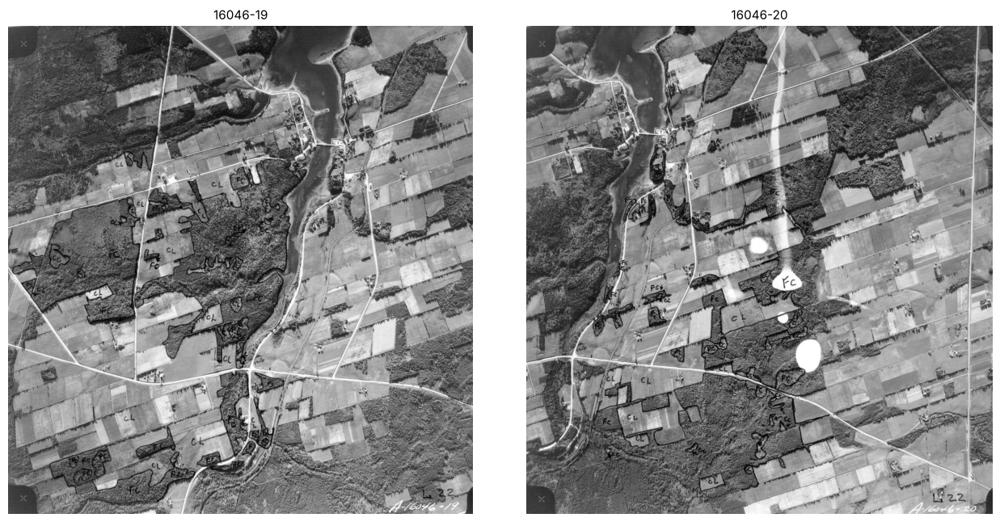

In [4]:
A = cv2.imread("frames/16046-19.jpg", cv2.IMREAD_GRAYSCALE)
B = cv2.imread("frames/16046-20.jpg", cv2.IMREAD_GRAYSCALE)

H_REF = np.array([[ 0.98700935, -0.00873884, -390.04915793],     # frame 19 -> frame 20
                  [ 0.00098735,  1.01974419,  -25.81833349],     # (1000-px frames)
                  [-0.00000007,  0.00002919,    1.        ]])
TOL = 5   # px

# Points of frame 19 that H_REF sends inside frame 20: the overlap, on a 10-px grid.
yy, xx = np.mgrid[0:A.shape[0]:10, 0:A.shape[1]:10]
grid = np.c_[xx.ravel(), yy.ravel()].astype(float)
g20 = project(grid, H_REF)
inside = (g20[:, 0] >= 0) & (g20[:, 0] < B.shape[1]) & (g20[:, 1] >= 0) & (g20[:, 1] < B.shape[0])
GRID, GRID_REF = grid[inside], g20[inside]

def align_err(H):
    # Mean distance (px) between where H and H_REF send the overlap grid.
    return np.linalg.norm(project(GRID, H) - GRID_REF, axis=1).mean()

print(f"frame 19: {A.shape[1]}x{A.shape[0]}   frame 20: {B.shape[1]}x{B.shape[0]}")
print(f"area overlap: {inside.mean():.0%} of frame 19 lands inside frame 20")
show([A, B], ["16046-19", "16046-20"], figw=13, figh=6.5)

---
## 1 · Candidate matches are not an alignment

SIFT, brute-force L2 matching and the ratio test — exactly where L7 and AL5 left off. (AL5 used
FLANN, which is approximate, so its counts differ by a few dozen; brute force is exact and gives
the same numbers every run.)

In [5]:
sift = cv2.SIFT_create()
ka, da = sift.detectAndCompute(A, None)
kb, db = sift.detectAndCompute(B, None)
knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(da, db, k=2)

ratio = np.array([m.distance / n.distance for m, n in knn])
pa_all = np.float64([ka[m.queryIdx].pt for m, n in knn])     # every keypoint in 19 ...
pb_all = np.float64([kb[m.trainIdx].pt for m, n in knn])     # ... and its nearest neighbour in 20
right_all = np.linalg.norm(project(pa_all, H_REF) - pb_all, axis=1) < TOL

print(f"{len(ka):,} keypoints in 19, {len(kb):,} in 20\n")
print(f"{'':16} {'kept':>7} {'correct':>8} {'wrong':>6} {'precision':>10}")
for r in (0.6, 0.7, 0.8, 0.9, None):
    keep = ratio < r if r else np.ones(len(ratio), bool)
    lab = f"ratio < {r}" if r else "nearest neighbour"
    print(f"{lab:16} {keep.sum():7,} {right_all[keep].sum():8,} {(~right_all[keep]).sum():6,} "
          f"{100*right_all[keep].mean():9.1f}%")

sel = ratio < 0.8
P, Q, RIGHT = pa_all[sel], pb_all[sel], right_all[sel]      # the candidates we carry forward

11,654 keypoints in 19, 11,239 in 20

                    kept  correct  wrong  precision
ratio < 0.6          936      932      4      99.6%
ratio < 0.7        1,232    1,219     13      98.9%
ratio < 0.8        1,628    1,497    131      92.0%
ratio < 0.9        2,858    1,714  1,144      60.0%
nearest neighbour  11,654    1,916  9,738      16.4%


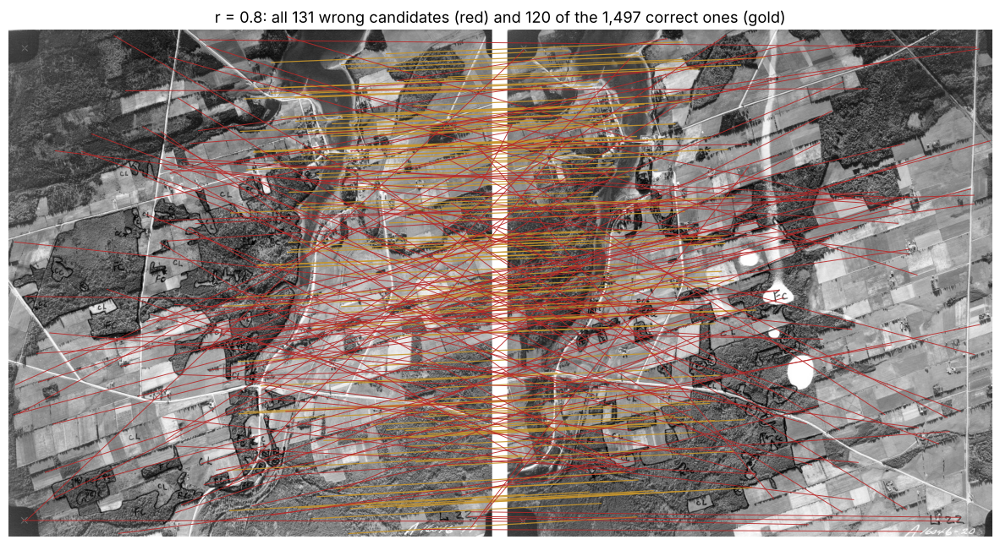

In [6]:
# Draw them: every wrong candidate in red, plus 120 random correct ones in gold.
rng = np.random.default_rng(1)
show_i = np.r_[np.where(~RIGHT)[0], rng.choice(np.where(RIGHT)[0], 120, replace=False)]
canvas = np.hstack([cv2.cvtColor(A, cv2.COLOR_GRAY2RGB), np.full((A.shape[0], 30, 3), 255, np.uint8),
                    cv2.cvtColor(B, cv2.COLOR_GRAY2RGB)])
off = A.shape[1] + 30
plt.figure(figsize=(15, 8)); plt.imshow(canvas); plt.axis('off')
for i in show_i[::-1]:
    c = GOLD if RIGHT[i] else RED
    plt.plot([P[i, 0], Q[i, 0] + off], [P[i, 1], Q[i, 1]], c=c, lw=0.9 if RIGHT[i] else 0.7, alpha=0.9)
plt.title(f"r = 0.8: all {(~RIGHT).sum()} wrong candidates (red) and 120 of the {RIGHT.sum():,} correct ones (gold)")
plt.show()

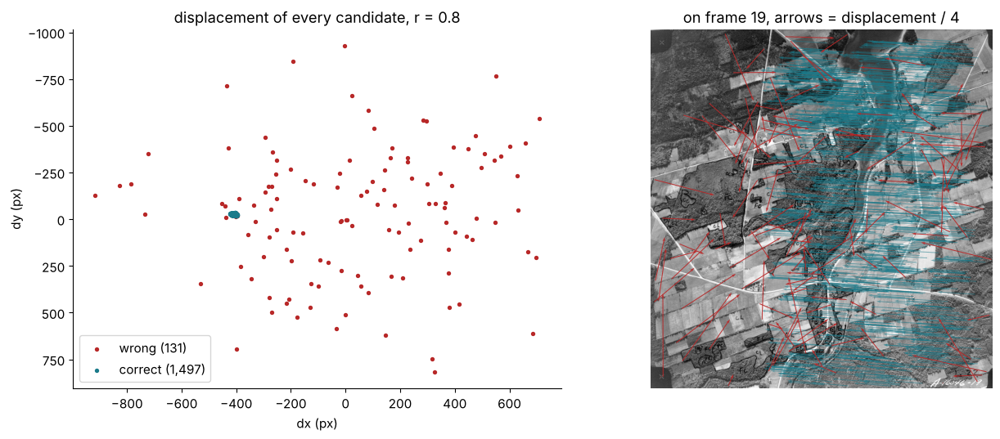

In [7]:
# What do the wrong ones look like? Plot each match's displacement (where it moved).
d = Q - P
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].scatter(d[~RIGHT, 0], d[~RIGHT, 1], s=8, c=RED, label=f"wrong ({(~RIGHT).sum()})")
ax[0].scatter(d[RIGHT, 0], d[RIGHT, 1], s=8, c=TEAL, label=f"correct ({RIGHT.sum():,})")
ax[0].set_xlabel("dx (px)"); ax[0].set_ylabel("dy (px)"); ax[0].legend(loc="lower left")
ax[0].set_title("displacement of every candidate, r = 0.8")
ax[0].invert_yaxis()

# The same matches drawn on frame 19 as arrows (scaled down so they fit)
ax[1].imshow(A, cmap='gray'); ax[1].axis('off')
for ok, col in ((True, TEAL), (False, RED)):
    m = RIGHT == ok
    ax[1].quiver(P[m, 0], P[m, 1], d[m, 0], d[m, 1], color=col, angles='xy',
                 scale_units='xy', scale=4, width=0.0025, alpha=0.9 if not ok else 0.5)
ax[1].set_title("on frame 19, arrows = displacement / 4")
plt.tight_layout(); plt.show()

The correct matches form one tight cluster: every point moved by roughly (−400, −25) px,
with small, *smooth* variation across the frame (the camera is not exactly straight down,
the ground is not exactly flat). The wrong ones are scattered everywhere. AL5's `consistent()`
used that cluster: the median shift. That only works for a **translation**. Today we fit the
full model and let the data decide which matches belong to it.

### 1.1 — Recap: what AL5's one shift missed

AL5 Part 2 summarised this pair with a single number: the **median displacement** of the
matches, and kept every match within 20 px of it (`consistent()`). Re-run that here on our
brute-force candidates, then compare the one shift with the reference homography `H_REF`
everywhere in the overlap.

In [8]:
def consistent(pa, pb, tol=20):                           # AL5 Task 2, unchanged
    d = pb - pa
    shift = np.median(d, axis=0)
    ok = np.linalg.norm(d - shift, axis=1) < tol
    return shift, ok

T_MED, ok = consistent(P, Q)
print(f"AL5's median shift: dx = {T_MED[0]:.0f}, dy = {T_MED[1]:.0f} px   "
      f"(forward overlap ≈ {1 + T_MED[0]/A.shape[1]:.0%})")
print(f"consistent(tol=20): keeps {ok.sum():,} of {len(P):,}, precision {100*RIGHT[ok].mean():.1f}%, "
      f"recall {100*ok[RIGHT].mean():.1f}%")

# Where H_REF sends each overlap point, minus where the one shift sends it
miss = GRID_REF - (GRID + T_MED)
mag = np.linalg.norm(miss, axis=1)
print(f"one shift vs H_REF over the overlap: mean {mag.mean():.1f} px, 90th pct {np.percentile(mag, 90):.1f} px, "
      f"max {mag.max():.1f} px")
print("\nH_REF =\n", np.array2string(H_REF, precision=5, suppress_small=False))

AL5's median shift: dx = -403, dy = -23 px   (forward overlap ≈ 58%)
consistent(tol=20): keeps 1,504 of 1,628, precision 99.5%, recall 99.9%
one shift vs H_REF over the overlap: mean 6.8 px, 90th pct 14.9 px, max 25.3 px

H_REF =
 [[ 9.87009e-01 -8.73884e-03 -3.90049e+02]
 [ 9.87350e-04  1.01974e+00 -2.58183e+01]
 [-7.00000e-08  2.91900e-05  1.00000e+00]]


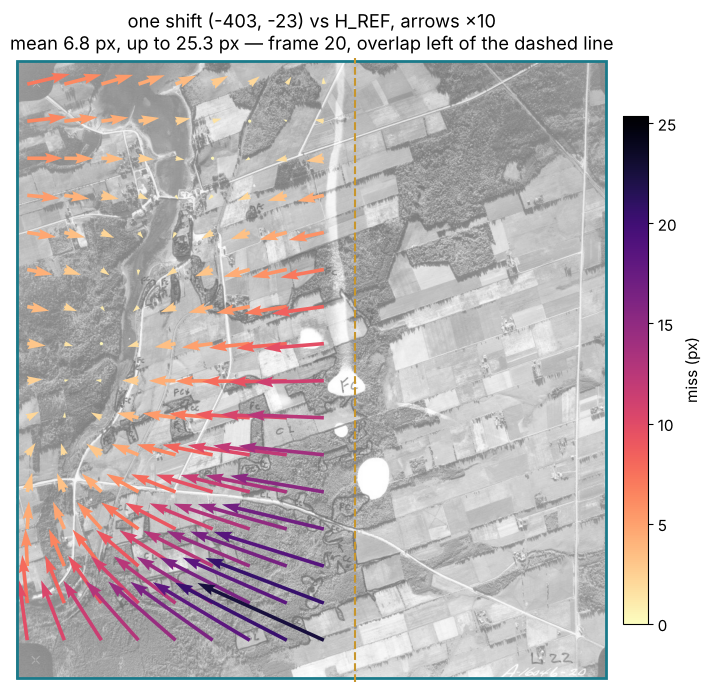

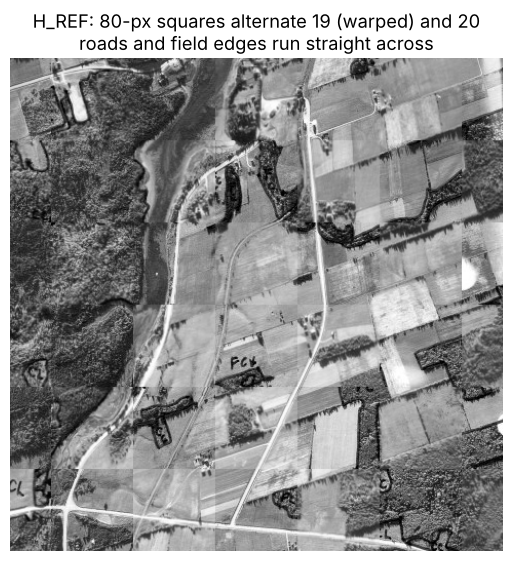

In [9]:
# What one shift misses: arrows (x10) from the shift's prediction to H_REF's, drawn on frame 20
fig, ax = plt.subplots(figsize=(7.2, 7.6))
ax.imshow(B, cmap='gray', alpha=0.55)
sub = (GRID[:, 0] % 60 == 0) & (GRID[:, 1] % 60 == 0)
pred = (GRID + T_MED)[sub]
q = ax.quiver(pred[:, 0], pred[:, 1], 10*miss[sub, 0], 10*miss[sub, 1], mag[sub], cmap='magma_r',
              angles='xy', scale_units='xy', scale=1, width=0.006, clim=(0, mag.max()))
cb = fig.colorbar(q, ax=ax, fraction=0.04, pad=0.02); cb.set_label("miss (px)")
ax.add_patch(plt.Rectangle((0, 0), B.shape[1]-1, B.shape[0]-1, fill=False, ec=TEAL, lw=2))
ax.axvline(GRID_REF[:, 0].max(), c=GOLD, lw=1.5, ls='--')               # right edge of the overlap
ax.set_xlim(-5, B.shape[1] + 5); ax.set_ylim(B.shape[0] + 5, -5); ax.axis('off')
ax.set_title(f"one shift ({T_MED[0]:.0f}, {T_MED[1]:.0f}) vs H_REF, arrows ×10\n"
             f"mean {mag.mean():.1f} px, up to {mag.max():.1f} px — frame 20, overlap left of the dashed line")
plt.tight_layout(); plt.show()

# And the proof that H_REF is right: AL5's checkerboard, zoomed on frame 20's overlap
A_in_B = cv2.warpPerspective(A, H_REF, (B.shape[1], B.shape[0]))
valid = cv2.warpPerspective(np.full_like(A, 255), H_REF, (B.shape[1], B.shape[0])) > 0
yy_, xx_ = np.mgrid[:B.shape[0], :B.shape[1]]
cb_img = np.where(((yy_ // 80 + xx_ // 80) % 2 == 0) & valid, A_in_B, B)
plt.figure(figsize=(6.4, 6.4)); plt.imshow(cb_img[240:720, 40:520], cmap='gray'); plt.axis('off')
plt.title("H_REF: 80-px squares alternate 19 (warped) and 20\nroads and field edges run straight across")
plt.show()

---
## 2 · Motion models and homogeneous coordinates

| Model | Matrix | DOF | Matches needed | Preserves |
|---|---|---|---|---|
| Translation | $\begin{bmatrix}1&0&t_x\\0&1&t_y\end{bmatrix}$ | 2 | 1 | orientation, lengths |
| Euclidean (rigid) | $\begin{bmatrix}R&t\end{bmatrix}$ | 3 | 2 | lengths |
| Similarity | $\begin{bmatrix}sR&t\end{bmatrix}$ | 4 | 2 | angles |
| Affine | $\begin{bmatrix}a_{11}&a_{12}&t_x\\a_{21}&a_{22}&t_y\end{bmatrix}$ | 6 | 3 | parallel lines |
| Projective (homography) | $3\times3$ $H$, up to scale | 8 | 4 | straight lines |

Each match gives **two** equations (one for $x$, one for $y$), so a model with $k$ degrees
of freedom needs $\lceil k/2 \rceil$ matches.

**Homogeneous coordinates.** Write the point $(x, y)$ as $(x, y, 1)$. A homography is a
$3\times3$ matrix; multiply, then divide by the third coordinate:

$$\begin{bmatrix}x'\\y'\\w'\end{bmatrix} = H\begin{bmatrix}x\\y\\1\end{bmatrix}, \qquad
(x', y') \leftarrow \left(\frac{x'}{w'}, \frac{y'}{w'}\right).$$

Because of that division, $H$ and $2H$ do the same thing — 9 numbers, 8 degrees of freedom.
We usually fix $h_{33} = 1$. The bottom row is what makes it *projective*: if it is
$(0, 0, 1)$ then $w' = 1$ and $H$ is just an affine map.

In [10]:
# By hand: where does pixel (500, 500) of frame 19 land in frame 20?
x = np.array([500, 500, 1.0])
xp = H_REF @ x
print("H_REF @ [500, 500, 1] =", np.round(xp, 4))
print(f"divide by w' = {xp[2]:.5f}  ->  ({xp[0]/xp[2]:.1f}, {xp[1]/xp[2]:.1f})")
print(f"project()                ->  {np.round(project(x[None, :2], H_REF)[0], 1)}")

H_REF @ [500, 500, 1] = [ 99.0861 484.5474   1.0146]
divide by w' = 1.01456  ->  (97.7, 477.6)
project()                ->  [ 97.7 477.6]


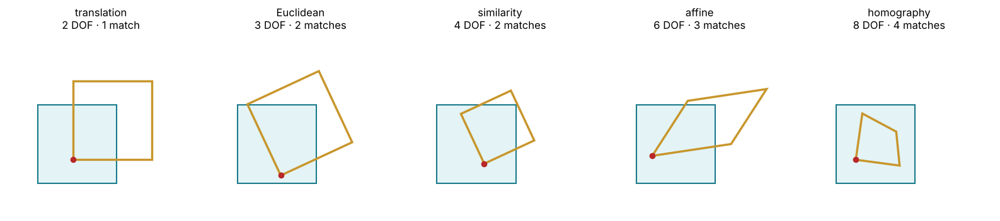

In [11]:
# A unit square under each model
sq = np.array([[0, 0], [1, 0], [1, 1], [0, 1]], float)
th = np.radians(25)
R2 = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
models = {
    "translation\n2 DOF · 1 match":  np.array([[1, 0, .45], [0, 1, .3], [0, 0, 1]]),
    "Euclidean\n3 DOF · 2 matches":  np.r_[np.c_[R2, [.55, .1]], [[0, 0, 1]]],
    "similarity\n4 DOF · 2 matches": np.r_[np.c_[0.7*R2, [.6, .25]], [[0, 0, 1]]],
    "affine\n6 DOF · 3 matches":     np.array([[1.0, .45, .2], [.15, .7, .35], [0, 0, 1]]),
    "homography\n8 DOF · 4 matches": np.array([[1.0, .2, .25], [.05, .9, .3], [.55, .35, 1]]),
}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
for ax, (name, M) in zip(axes, models.items()):
    q = project(sq, M)
    ax.fill(*sq.T, fc="#E4F4F6", ec=TEAL, lw=1.5)
    ax.fill(*q.T, fc="none", ec=GOLD, lw=2.5)
    ax.plot(*q[0], 'o', c=RED)
    ax.set_xlim(-0.4, 2.0); ax.set_ylim(-0.4, 1.9); ax.set_aspect('equal')
    ax.set_title(name, fontsize=12); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.show()

### 2.1 — Match the transformation

Below, the same 360 × 360 px piece of frame 19 — with a gold grid drawn on it and a red dot on
its top-left corner — has been warped six ways (**A–F**). Panel **G** is the real thing: frame 19
warped by `H_REF` into frame 20's coordinates (frame 20's outline in teal).

For each panel, name the **simplest** model that explains it: *translation*, *rigid*,
*similarity*, *affine* or *homography*. Labels can repeat. Every translation is also an affine
map and a homography, so "simplest" is what makes the answer unique — and it is the one RANSAC
cares about, because fewer degrees of freedom means a smaller sample.

Clues to check, in order: did **lengths** change? did **angles** change (do the grid squares
stay square)? do **parallel lines** stay parallel?

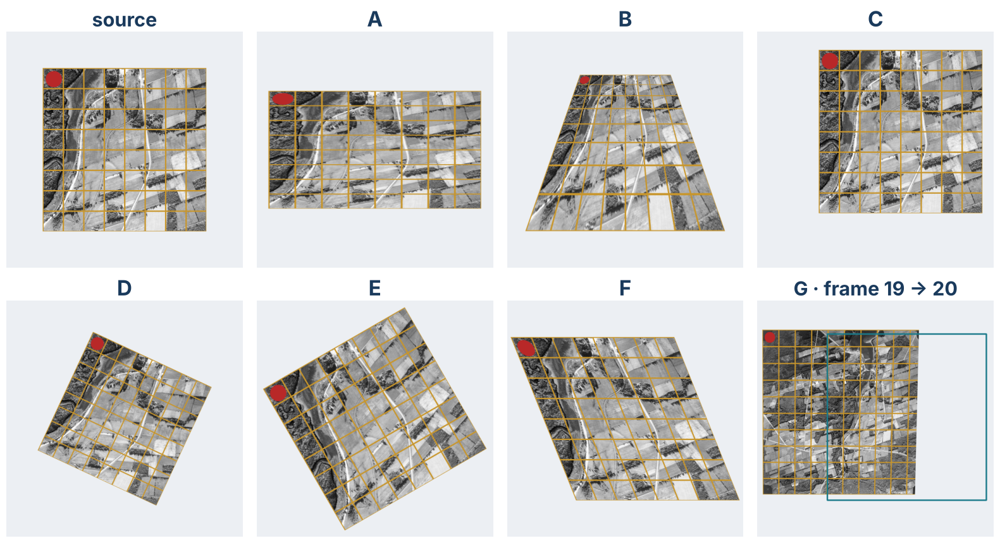

In [12]:
# Source: 360 x 360 px of frame 19 with a grid and a corner marker, on a 520 x 520 canvas.
SRC = cv2.cvtColor(A[300:660, 520:880], cv2.COLOR_GRAY2RGB)
for k in range(0, 361, 45):
    cv2.line(SRC, (k, 0), (k, 360), (200, 150, 44), 2); cv2.line(SRC, (0, k), (360, k), (200, 150, 44), 2)
cv2.circle(SRC, (24, 24), 18, (184, 40, 40), -1)
CAN, OFF = 520, 80
c = OFF + 180                                            # centre of the source on the canvas

def T(tx, ty): return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1.]])
def about_centre(L):                                      # apply the 2x2 L about the source centre
    return T(c, c) @ np.r_[np.c_[L, [0, 0]], [[0, 0, 1]]] @ T(-c, -c)
def R(deg):
    t = np.radians(deg); return np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])

sq = np.float32([[OFF, OFF], [OFF+360, OFF], [OFF+360, OFF+360], [OFF, OFF+360]])
trap = np.float32([[160, 95], [360, 95], [480, 440], [40, 440]])
PANELS = {                                                # 3x3 matrices acting on canvas coordinates
    "A": about_centre(np.diag([1.3, 0.72])),             # different x and y scales
    "B": cv2.getPerspectiveTransform(sq, trap).astype(float),
    "C": T(55, -40),
    "D": about_centre(0.8 * R(25)),
    "E": about_centre(R(-30)),
    "F": about_centre(np.array([[1, 0.4], [0, 1]])),     # shear
}

def place(M):
    # Warp the source (already offset to the canvas) by M; light-grey background.
    return cv2.warpPerspective(SRC, M @ T(OFF, OFF), (CAN, CAN), borderValue=(236, 239, 243))

fig, axes = plt.subplots(2, 4, figsize=(16, 8.6))
axes = axes.ravel()
axes[0].imshow(place(np.eye(3))); axes[0].set_title("source", fontsize=22, fontweight='bold', color=NAVY)
for ax, (k, M) in zip(axes[1:7], PANELS.items()):
    ax.imshow(place(M)); ax.set_title(k, fontsize=24, fontweight='bold', color=NAVY)

# G: the real pair. Frame 19 (with a 100-px grid) warped by H_REF into frame 20's coordinates.
g19 = cv2.cvtColor(A, cv2.COLOR_GRAY2RGB)
for k in range(0, 1001, 100):
    cv2.line(g19, (k, 0), (k, 1000), (200, 150, 44), 5); cv2.line(g19, (0, k), (1000, k), (200, 150, 44), 5)
cv2.circle(g19, (45, 45), 32, (184, 40, 40), -1)
TG = T(420, 200)                                          # frame 20's top-left sits at (420, 200)
G = cv2.warpPerspective(g19, TG @ H_REF, (1420, 1420), borderValue=(236, 239, 243))
cv2.rectangle(G, (420, 200), (420 + B.shape[1], 200 + B.shape[0]), (26, 122, 138), 8)
axes[7].imshow(G); axes[7].set_title("G · frame 19 → 20", fontsize=22, fontweight='bold', color=NAVY)
for ax in axes: ax.axis('off')
plt.subplots_adjust(left=0.01, right=0.99, top=0.94, bottom=0.01, wspace=0.04, hspace=0.14); plt.show()

**Decide before you run the next cell.** It classifies each matrix with three tests that mirror
the visual clues: is the bottom row $(0, 0, 1)$ (parallel lines stay parallel)? Is the $2\times2$
part $L$ the identity (translation)? Is $L^\top L = s^2 I$ (angles kept: similarity, or rigid if $s = 1$)?

In [13]:
def simplest_model(M, tol=1e-9):
    M = M / M[2, 2]
    if np.abs(M[2, :2]).max() > tol:
        return "homography"
    L = M[:2, :2]
    if np.allclose(L, np.eye(2)):
        return "translation"
    LtL = L.T @ L
    if np.allclose(LtL, LtL[0, 0] * np.eye(2)):
        return "rigid" if np.isclose(LtL[0, 0], 1) else "similarity"
    return "affine"

why = {"A": "squares became rectangles: x × 1.3, y × 0.72 — not one scale, so not a similarity",
       "B": "the grid's vertical lines converge",
       "C": "nothing turned or stretched; every point moved by (55, −40)",
       "D": "turned 25° and shrank to 0.8×; squares stay square",
       "E": "turned 30° about the centre — the matrix still has a translation column",
       "F": "shear: squares became parallelograms, lines stay parallel",
       "G": "looks like a translation; the bottom row says otherwise"}
for k, M in list(PANELS.items()) + [("G", H_REF)]:
    print(f"{k}: {simplest_model(M):11}  {why[k]}")

L = H_REF[:2, :2]
print(f"\nG in numbers: rotation {np.degrees(np.arctan2(L[1, 0], L[0, 0])):.2f}°, "
      f"x-scale {np.linalg.norm(L[:, 0]):.3f}, y-scale {np.linalg.norm(L[:, 1]):.3f}, "
      f"h32 = {H_REF[2, 1]:.1e} -> w' changes by {100*H_REF[2, 1]*A.shape[0]:.1f}% from top to bottom")

A: affine       squares became rectangles: x × 1.3, y × 0.72 — not one scale, so not a similarity
B: homography   the grid's vertical lines converge
C: translation  nothing turned or stretched; every point moved by (55, −40)
D: similarity   turned 25° and shrank to 0.8×; squares stay square
E: rigid        turned 30° about the centre — the matrix still has a translation column
F: affine       shear: squares became parallelograms, lines stay parallel
G: homography   looks like a translation; the bottom row says otherwise

G in numbers: rotation 0.06°, x-scale 0.987, y-scale 1.020, h32 = 2.9e-05 -> w' changes by 2.9% from top to bottom


**G is the point of the exercise.** By eye it is a translation — the frame moved about 390 px
left. In numbers it also shrinks 1.3% in $x$, stretches 2.0% in $y$ (so not even a similarity),
and has a perspective term that changes the scale by about 3% from the top of the frame to the
bottom: a homography. Your eye cannot see 3%; residuals can. Section 7.1
fits each model to the matches and shows what each one costs in pixels.

### 2.2 — When is a homography *exactly* right?

A homography maps one plane to another plane. Two photographs are related by a homography when

1. **the scene is a plane** — any camera motion at all (a document, a wall, flat farmland seen
   from 3,000 m), or
2. **the camera only rotates** about its optical centre — any scene at all (a panorama on a
   tripod).

Otherwise, points at different depths shift by different amounts as the camera moves
(**parallax**) and no single $H$ fits them all. That is L11's problem (stereo).

PEI from 1958 altitude is *nearly* a plane: the relief over this frame is a few tens of metres
against a flying height of several kilometres. Trees and the forestry ink on the prints are
what breaks it.

---
## 3 · Estimating a homography: the Direct Linear Transform

For one match $(x, y) \to (u, v)$, write $H$'s rows as $\mathbf h_1, \mathbf h_2, \mathbf h_3$
and $\mathbf x = (x, y, 1)$. Then $u = \mathbf h_1\cdot\mathbf x \,/\, \mathbf h_3\cdot\mathbf x$.
Multiply out the division and it is **linear in the nine entries of $H$**:

$$\mathbf h_1\cdot\mathbf x - u\,(\mathbf h_3\cdot\mathbf x) = 0, \qquad
\mathbf h_2\cdot\mathbf x - v\,(\mathbf h_3\cdot\mathbf x) = 0.$$

Two rows of a matrix $\mathbf A$ per match; stack $N$ matches into a $2N\times9$ system
$\mathbf A\mathbf h = \mathbf 0$. We want $\mathbf h \ne \mathbf 0$, so fix $\lVert\mathbf h\rVert = 1$
and minimise $\lVert\mathbf A\mathbf h\rVert$: the answer is the **right singular vector with the
smallest singular value** — the last row of $V^\top$ from `np.linalg.svd`. (SVD is Wednesday's L9.)

With exactly 4 matches, $\mathbf A$ is $8\times9$ and the solution is exact. With more, it is a
least-squares fit.

**Normalise first** (Hartley 1997). Pixel coordinates run 0–1000, so the entries of $\mathbf A$
range from 1 to $10^6$ and the SVD is badly conditioned. Shift each point set to have its
centroid at the origin and scale it so the average distance from the origin is $\sqrt2$, solve,
then undo: $H = T_2^{-1}\,\tilde H\,T_1$.

In [14]:
def normaliser(p):
    # 3x3 T: centroid -> origin, mean distance from origin -> sqrt(2)
    c = p.mean(0)
    s = np.sqrt(2) / np.linalg.norm(p - c, axis=1).mean()
    return np.array([[s, 0, -s*c[0]], [0, s, -s*c[1]], [0, 0, 1]])

def dlt_matrix(p, q):
    x, y, u, v = p[:, 0], p[:, 1], q[:, 0], q[:, 1]
    z, o = np.zeros_like(x), np.ones_like(x)
    r1 = np.c_[-x, -y, -o,  z,  z,  z, u*x, u*y, u]
    r2 = np.c_[ z,  z,  z, -x, -y, -o, v*x, v*y, v]
    return np.vstack([r1, r2])                       # (2N, 9)

def dlt(p, q, normalise=True):
    # Homography mapping p -> q (both (N, 2), N >= 4), by SVD.
    if normalise:
        T1, T2 = normaliser(p), normaliser(q)
        p, q = project(p, T1), project(q, T2)
    _, S, Vt = np.linalg.svd(dlt_matrix(p, q))
    H = Vt[-1].reshape(3, 3)
    if normalise:
        H = np.linalg.inv(T2) @ H @ T1
    return H / H[2, 2]

# Fit to the *correct* candidates only (we can, because we know which they are)
H_true = dlt(P[RIGHT], Q[RIGHT])
print(f"DLT on the {RIGHT.sum():,} correct candidates: mean alignment error vs H_REF "
      f"= {align_err(H_true):.2f} px")
print(np.round(H_true, 5))

DLT on the 1,497 correct candidates: mean alignment error vs H_REF = 0.67 px
[[ 9.8478000e-01 -6.5800000e-03 -3.8924212e+02]
 [ 9.3000000e-04  1.0198800e+00 -2.5670070e+01]
 [ 0.0000000e+00  3.0000000e-05  1.0000000e+00]]


In [15]:
# Why normalise? Conditioning of A, and what noise does to the answer.
rng = np.random.default_rng(8)
pt, qt = P[RIGHT], Q[RIGHT]
for norm in (False, True):
    p, q = (pt, qt) if not norm else (project(pt, normaliser(pt)), project(qt, normaliser(qt)))
    S = np.linalg.svd(dlt_matrix(p, q), compute_uv=False)
    print(f"{'normalised' if norm else 'raw pixels':11}: singular values {S[0]:.3g} … {S[-2]:.3g}, "
          f"condition number s1/s8 = {S[0]/S[-2]:.3g}")

print("\nFit from n random correct matches, 200 trials each (median alignment error vs H_REF):")
for n in (4, 8, 50):
    row = []
    for norm in (False, True):
        errs = [align_err(dlt(pt[i], qt[i], normalise=norm))
                for i in (rng.choice(len(pt), n, replace=False) for _ in range(200))]
        row.append(np.median(errs))
    print(f"  n = {n:2d}:  raw pixels {row[0]:6.2f} px    normalised {row[1]:6.2f} px")

raw pixels : singular values 2.09e+07 … 4.47, condition number s1/s8 = 4.66e+06
normalised : singular values 118 … 26.1, condition number s1/s8 = 4.5

Fit from n random correct matches, 200 trials each (median alignment error vs H_REF):


  n =  4:  raw pixels  12.71 px    normalised  13.55 px
  n =  8:  raw pixels   1.71 px    normalised   1.68 px


  n = 50:  raw pixels   0.79 px    normalised   0.82 px


Normalising drops the condition number from about $5\times10^{6}$ to under 5. On *this* pair the
answer barely changes — the points are well spread, the frames are only 1000 px, and NumPy
works in double precision. Normalise anyway: it costs two 3×3 matrices, and with large
coordinates (a 30,000-px mosaic), single precision, or the 8-point algorithm for stereo
(L11) it is the difference between working and not. OpenCV normalises for you.

Look at the other column of numbers instead: **a fit from exactly 4 matches is off by about
13 px**, even when all four are correct. Four points fit their own noise perfectly and
extrapolate it across the frame. Fifty points average it out. Remember this in section 5.

---
## 4 · Least squares meets outliers

Section 3 cheated: we used `H_REF` to pick out the correct matches first. In real life we
only have the candidates, and 8% of them are wrong. What does a least-squares fit to all of
them give?

In [16]:
H_ls = dlt(P, Q)
print(f"DLT on all {len(P):,} candidates ({(~RIGHT).sum()} wrong): "
      f"mean alignment error {align_err(H_ls):,.0f} px")
print(np.round(H_ls, 5))

# How many outliers does it take?  Start from 300 correct matches, add k wrong ones.
rng = np.random.default_rng(1)
good_i = rng.choice(np.where(RIGHT)[0], 300, replace=False)
bad_i = rng.permutation(np.where(~RIGHT)[0])
ks = [0, 1, 2, 5, 10, 20, 50, 100]
ls_err = []
for k in ks:
    i = np.r_[good_i, bad_i[:k]]
    ls_err.append(align_err(dlt(P[i], Q[i])))
    print(f"  300 correct + {k:3d} wrong ({100*k/(300+k):4.1f}% outliers): {ls_err[-1]:10.1f} px")

DLT on all 1,628 candidates (131 wrong): mean alignment error 82 px
[[-1.54407300e+01 -6.63710000e-01  6.97053816e+03]
 [-8.84672000e+00 -1.21554800e+01  6.48696505e+03]
 [-1.78000000e-02 -8.80000000e-04  1.00000000e+00]]
  300 correct +   0 wrong ( 0.0% outliers):        0.6 px
  300 correct +   1 wrong ( 0.3% outliers):        2.1 px
  300 correct +   2 wrong ( 0.7% outliers):       14.2 px
  300 correct +   5 wrong ( 1.6% outliers):       18.6 px
  300 correct +  10 wrong ( 3.2% outliers):       44.2 px
  300 correct +  20 wrong ( 6.2% outliers):       82.0 px
  300 correct +  50 wrong (14.3% outliers):      134.2 px


  300 correct + 100 wrong (25.0% outliers):      186.6 px


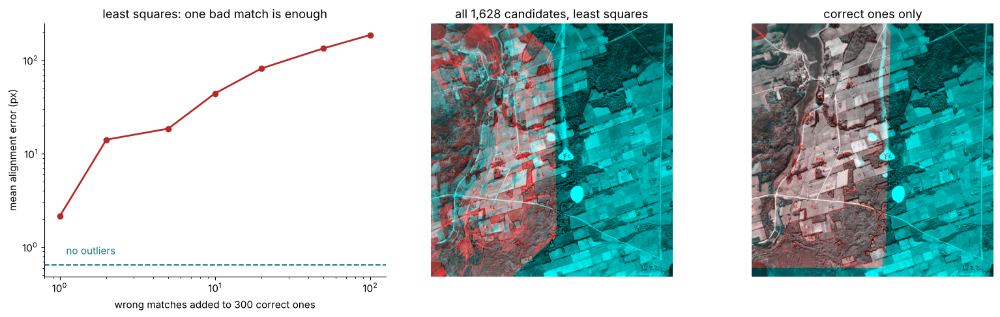

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax[0].plot(ks[1:], ls_err[1:], 'o-', c=RED, lw=2)
ax[0].axhline(ls_err[0], c=TEAL, ls='--'); ax[0].text(1.1, ls_err[0]*1.3, "no outliers", color=TEAL)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel("wrong matches added to 300 correct ones"); ax[0].set_ylabel("mean alignment error (px)")
ax[0].set_title("least squares: one bad match is enough")

def overlay(H, title, a):
    w19 = cv2.warpPerspective(A, H, (B.shape[1], B.shape[0]))
    rgb = np.dstack([w19, B, B])                     # red = warped 19, cyan = 20
    a.imshow(rgb); a.set_title(title); a.axis('off')
overlay(H_ls, f"all {len(P):,} candidates, least squares", ax[1])
overlay(H_true, "correct ones only", ax[2])
plt.tight_layout(); plt.show()

Squared error gives a match that is 500 px off 250,000 times the say of one that is 1 px off.
A single wrong match moves the answer by pixels; a handful destroy it. We need a fit that
**ignores** points that disagree, without knowing in advance which ones they are.

---
## 5 · RANSAC from scratch

**RAN**dom **SA**mple **C**onsensus (Fischler & Bolles, 1981). Flip the question: instead
of fitting to everything and hoping, fit to the *smallest possible* sample and count how
many points agree.

1. Pick $s$ matches at random — the minimum for the model ($s = 4$ for a homography).
2. Fit the model to those $s$ exactly.
3. Count the **inliers**: matches whose reprojection error $\lVert H\mathbf p - \mathbf q\rVert$ is below a threshold $\varepsilon$.
4. Keep the model with the most inliers. Repeat $N$ times.
5. Refit with least squares on all the inliers of the best model.

If any one sample is all inliers, its model will be roughly right, and roughly right is
enough for the correct matches to agree with it.

First, the idea on a line (2 points per sample), where you can see it.

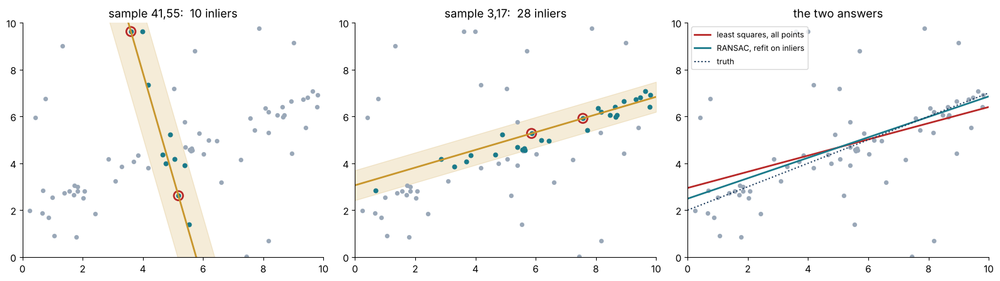

In [18]:
# Toy: 40 points on a line plus 30 scattered outliers
rng = np.random.default_rng(3950)
xs = rng.uniform(0, 10, 40); ys = 0.5*xs + 2 + rng.normal(0, 0.25, 40)
ox = rng.uniform(0, 10, 30); oy = rng.uniform(0, 10, 30)
X, Y = np.r_[xs, ox], np.r_[ys, oy]

def line_through(i, j):
    m = (Y[j]-Y[i]) / (X[j]-X[i]); return m, Y[i] - m*X[i]
def line_inliers(m, c, eps=0.6):
    return np.abs(m*X - Y + c) / np.hypot(m, 1) < eps

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
samples = [(41, 55), (3, 17)]
for a, (i, j) in zip(ax[:2], samples):
    m, c = line_through(i, j); inl = line_inliers(m, c)
    xx = np.array([0, 10])
    a.fill_between(xx, m*xx+c-0.6*np.hypot(m, 1), m*xx+c+0.6*np.hypot(m, 1), color=GOLD, alpha=0.18)
    a.plot(xx, m*xx+c, c=GOLD, lw=2)
    a.scatter(X[~inl], Y[~inl], s=18, c="#9AA8B8"); a.scatter(X[inl], Y[inl], s=22, c=TEAL)
    a.scatter(X[[i, j]], Y[[i, j]], s=110, facecolors='none', edgecolors=RED, linewidths=2)
    a.set_title(f"sample {i},{j}:  {inl.sum()} inliers"); a.set_xlim(0, 10); a.set_ylim(0, 10)
mls, cls = np.polyfit(X, Y, 1)
ax[2].scatter(X, Y, s=18, c="#9AA8B8")
ax[2].plot([0, 10], [cls, 10*mls+cls], c=RED, lw=2, label="least squares, all points")
m, c = line_through(*samples[1]); inl = line_inliers(m, c)
mr, cr = np.polyfit(X[inl], Y[inl], 1)
ax[2].plot([0, 10], [cr, 10*mr+cr], c=TEAL, lw=2, label="RANSAC, refit on inliers")
ax[2].plot([0, 10], [2, 7], c=NAVY, ls=':', label="truth")
ax[2].legend(loc="upper left", fontsize=9); ax[2].set_xlim(0, 10); ax[2].set_ylim(0, 10)
ax[2].set_title("the two answers")
plt.tight_layout(); plt.show()

In [19]:
def ransac_h(p, q, eps=3.0, iters=1000, seed=0):
    # RANSAC for a homography p -> q. Returns H, inlier mask, best-so-far inlier count per iteration.
    rng = np.random.default_rng(seed)
    best, history = np.zeros(len(p), bool), []
    for _ in range(iters):
        s = rng.choice(len(p), 4, replace=False)          # 1. minimal sample
        H = dlt(p[s], q[s])                               # 2. exact fit
        if np.all(np.isfinite(H)):
            err = np.linalg.norm(project(p, H) - q, axis=1)
            inl = err < eps                               # 3. consensus
            if inl.sum() > best.sum():                    # 4. keep the best
                best = inl
        history.append(best.sum())
    H = dlt(p[best], q[best])                             # 5. refit on all inliers
    inl = np.linalg.norm(project(p, H) - q, axis=1) < eps
    return H, inl, np.array(history)

t0 = time.perf_counter()
H_r, inl, hist = ransac_h(P, Q)
RANSAC_TIME = time.perf_counter() - t0
print(f"{RANSAC_TIME:.2f} s for 1,000 iterations")
print(f"inliers {inl.sum():,} of {len(P):,}   precision {100*RIGHT[inl].mean():.1f}%   "
      f"recall {100*inl[RIGHT].mean():.1f}% of the correct candidates")
print(f"mean alignment error vs H_REF: {align_err(H_r):.2f} px   (least squares on everything: {align_err(H_ls):,.0f} px)")
first = np.argmax(hist >= 0.95*hist[-1])
print(f"best-so-far reached 95% of its final count at iteration {first + 1}")

0.54 s for 1,000 iterations
inliers 1,418 of 1,628   precision 100.0%   recall 94.7% of the correct candidates
mean alignment error vs H_REF: 0.73 px   (least squares on everything: 82 px)
best-so-far reached 95% of its final count at iteration 89


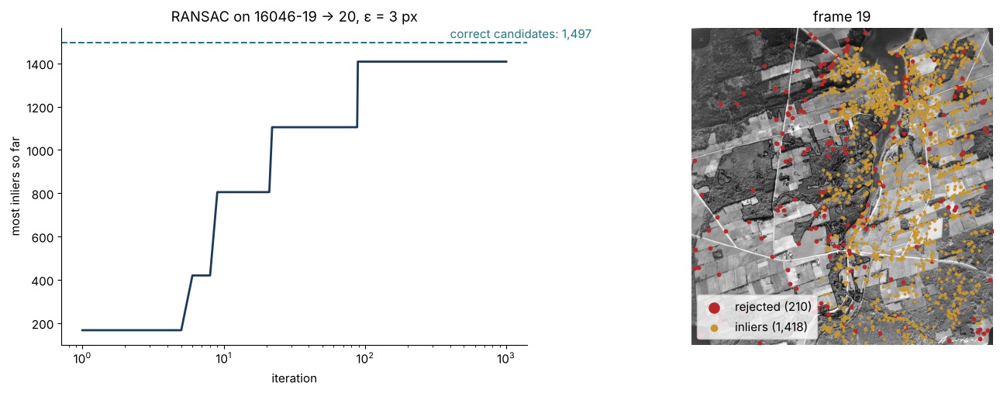

79 correct candidates rejected: median error 3.2 px under H_REF, 3.4 px under our fit — they are the loosest of the 'correct' ones (within 5 px, outside 3 px)


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].plot(np.arange(1, len(hist)+1), hist, c=NAVY, lw=2)
ax[0].axhline(RIGHT.sum(), c=TEAL, ls='--'); ax[0].text(400, RIGHT.sum()+20, f"correct candidates: {RIGHT.sum():,}", color=TEAL)
ax[0].set_xscale('log'); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("most inliers so far")
ax[0].set_title("RANSAC on 16046-19 → 20, ε = 3 px")

ax[1].imshow(A, cmap='gray'); ax[1].axis('off')
ax[1].scatter(*P[~inl].T, s=10, c=RED, label=f"rejected ({(~inl).sum()})")
ax[1].scatter(*P[inl].T, s=4, c=GOLD, label=f"inliers ({inl.sum():,})")
ax[1].legend(loc="lower left", markerscale=3); ax[1].set_title("frame 19")
plt.tight_layout(); plt.show()

# Which correct candidates did RANSAC reject?  Their error under H_REF vs under the RANSAC fit.
miss = RIGHT & ~inl
e_ref = np.linalg.norm(project(P[miss], H_REF) - Q[miss], axis=1)
e_r = np.linalg.norm(project(P[miss], H_r) - Q[miss], axis=1)
print(f"{miss.sum()} correct candidates rejected: median error {np.median(e_ref):.1f} px under H_REF, "
      f"{np.median(e_r):.1f} px under our fit — they are the loosest of the 'correct' ones (within 5 px, outside 3 px)")

---
## 6 · How many iterations?

Let $w$ be the fraction of candidates that are inliers and $s$ the sample size. One sample
is all inliers with probability $w^s$. After $N$ samples, the chance that *none* was clean is
$(1 - w^s)^N$. To succeed with probability $p$ (say 0.99):

$$N = \frac{\log(1 - p)}{\log(1 - w^s)}.$$

In [21]:
def n_iters(w, s, p=0.99):
    return int(np.ceil(np.log(1 - p) / np.log(1 - w**s)))

ws = [0.9, 0.8, 0.5, 0.3, 0.2, 0.1]
print(f"{'w':>5} | " + " ".join(f"{'s='+str(s):>9}" for s in (1, 2, 3, 4, 8)))
for w in ws:
    print(f"{w:5.2f} | " + " ".join(f"{n_iters(w, s):9,}" for s in (1, 2, 3, 4, 8)))

w08 = RIGHT.mean(); wnn = right_all.mean()
print(f"\nour pair: ratio test 0.8 -> w = {w08:.3f}, N = {n_iters(w08, 4)}")
print(f"          no ratio test   -> w = {wnn:.3f}, N = {n_iters(wnn, 4):,}")

    w |       s=1       s=2       s=3       s=4       s=8
 0.90 |         2         3         4         5         9
 0.80 |         3         5         7         9        26
 0.50 |         7        17        35        72     1,177
 0.30 |        13        49       169       567    70,188
 0.20 |        21       113       574     2,876 1,798,893
 0.10 |        44       459     4,603    46,050 460,517,014

our pair: ratio test 0.8 -> w = 0.920, N = 4
          no ratio test   -> w = 0.164, N = 6,301


Two things to read off the table. The sample size $s$ sits in the **exponent**: translation
($s=1$) survives 90% outliers in 44 tries; a homography ($s=4$) needs 46,000. And the ratio
test is not optional: it raised $w$ from 16% to 92%, which cut $N$ by three orders of magnitude.

Is the formula right? Measure it: draw 50,000 random samples of 4 from each candidate set,
fit each, and see how often the sample is all inliers and how often the fitted $H$ is
actually good.

In [22]:
def batch_dlt(p, q):
    # Fit many homographies at once: p, q are (M, 4, 2). Normalised DLT with a batched SVD.
    c1, c2 = p.mean(1, keepdims=True), q.mean(1, keepdims=True)
    s1 = np.sqrt(2) / np.linalg.norm(p - c1, axis=2).mean(1)
    s2 = np.sqrt(2) / np.linalg.norm(q - c2, axis=2).mean(1)
    pn, qn = (p - c1) * s1[:, None, None], (q - c2) * s2[:, None, None]
    x, y, u, v = pn[..., 0], pn[..., 1], qn[..., 0], qn[..., 1]
    z, o = np.zeros_like(x), np.ones_like(x)
    r1 = np.stack([-x, -y, -o, z, z, z, u*x, u*y, u], -1)
    r2 = np.stack([z, z, z, -x, -y, -o, v*x, v*y, v], -1)
    Hn = np.linalg.svd(np.concatenate([r1, r2], 1))[2][:, -1].reshape(-1, 3, 3)
    T1 = np.zeros((len(p), 3, 3)); T1[:, 0, 0] = T1[:, 1, 1] = s1; T1[:, 2, 2] = 1
    T1[:, :2, 2] = -s1[:, None] * c1[:, 0]
    T2i = np.zeros((len(p), 3, 3)); T2i[:, 0, 0] = T2i[:, 1, 1] = 1/s2; T2i[:, 2, 2] = 1
    T2i[:, :2, 2] = c2[:, 0]
    H = T2i @ Hn @ T1
    return H / H[:, 2:, 2:]

def sample_quality(p, q, right, M=50_000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(p), (2*M, 4))                       # draw, then drop rows with a repeat
    idx = idx[(np.diff(np.sort(idx, 1), axis=1) > 0).all(1)][:M]
    Hs = batch_dlt(p[idx], q[idx])
    g, gref = np.c_[GRID[::4], np.ones(len(GRID[::4]))], GRID_REF[::4]   # every 4th grid point: plenty, 4x faster
    err = []
    for k in range(0, M, 5000):                       # alignment error of every sampled H
        G = np.einsum('mij,nj->mni', Hs[k:k+5000], g)
        err.append(np.linalg.norm(G[..., :2] / G[..., 2:] - gref, axis=2).mean(1))
    err = np.concatenate(err)
    clean = right[idx].all(1)
    return clean, err

for name, p, q, r in [("ratio 0.8", P, Q, RIGHT), ("no ratio test", pa_all, pb_all, right_all)]:
    clean, err = sample_quality(p, q, r)
    w = r.mean()
    good = err < 10
    print(f"{name:14} w = {w:.3f}:  all-inlier samples {100*clean.mean():6.2f}%  (w^4 predicts {100*w**4:6.2f}%)")
    print(f"{'':14} of the clean samples, {100*good[clean].mean():4.1f}% give an H within 10 px of H_REF "
          f"(median {np.median(err[clean]):.1f} px)")
    print(f"{'':14} of the dirty samples, {100*good[~clean].mean():4.2f}% do\n")

ratio 0.8      w = 0.920:  all-inlier samples  71.60%  (w^4 predicts  71.49%)
               of the clean samples, 47.5% give an H within 10 px of H_REF (median 10.9 px)
               of the dirty samples, 1.16% do



no ratio test  w = 0.164:  all-inlier samples   0.09%  (w^4 predicts   0.07%)
               of the clean samples, 51.1% give an H within 10 px of H_REF (median 9.8 px)
               of the dirty samples, 0.00% do



The $w^4$ prediction is right about clean samples. But a clean sample is not automatically
a good model: four inliers bunched in one corner, or nearly on a line, fit those four
perfectly and extrapolate badly across the frame. Only a fraction of clean samples land
within 10 px. That is why step 5 — refit on *all* the inliers — matters, and why practical
implementations add a *local optimisation* step (LO-RANSAC). The $N$ from the formula is the
right order of magnitude, not a guarantee.

**Adaptive $N$.** We rarely know $w$ in advance. Start pessimistic and, each time a better
model appears, set $w$ to its inlier fraction and recompute $N$. OpenCV does this; it is why
`findHomography` often stops after a few dozen iterations on a good pair.

---
## 7 · The inlier threshold, and which model to fit

$\varepsilon$ is the one number you choose. It should be a few times the localisation noise
of the keypoints — and it is in **pixels at the resolution you matched at**. Halve the image
and the same physical tolerance is half as many pixels.

In [23]:
print(f"{'eps (px)':>8} {'inliers':>8} {'precision':>10} {'recall':>7} {'align err':>10}")
eps_rows = []
for eps in (0.5, 1, 2, 3, 5, 10, 20, 50):
    H, m = cv2.findHomography(P, Q, cv2.RANSAC, eps)
    m = m.ravel().astype(bool)
    eps_rows.append((eps, m.sum(), RIGHT[m].mean(), m[RIGHT].mean(), align_err(H)))
    print(f"{eps:8} {m.sum():8,} {100*RIGHT[m].mean():9.1f}% {100*m[RIGHT].mean():6.1f}% {align_err(H):9.2f} px")

eps (px)  inliers  precision  recall  align err
     0.5      297     100.0%   19.8%      0.59 px
       1      643     100.0%   43.0%      2.16 px
       2    1,144     100.0%   76.4%      0.92 px
       3    1,411     100.0%   94.3%      0.74 px
       5    1,497     100.0%  100.0%      0.70 px
      10    1,505      99.5%  100.0%      0.68 px
      20    1,505      99.5%  100.0%      0.68 px
      50    1,506      99.4%  100.0%      0.71 px


Too small and RANSAC rejects good matches whose keypoints are a pixel or two off; too
large and wrong matches start to vote. Between about 3 and 10 px the answer barely moves —
on a clean pair the threshold is forgiving. It is not forgiving when the true model does not
fit (parallax), because then $\varepsilon$ decides how much misfit you accept.

### 7.1 — Which motion model?

Fit each model with RANSAC at $\varepsilon = 3$ px and compare residuals on the shared inliers.

In [24]:
def ransac_translation(p, q, eps=3.0, iters=200, seed=0):
    rng = np.random.default_rng(seed); best = None
    for _ in range(iters):
        i = rng.integers(len(p)); t = q[i] - p[i]
        inl = np.linalg.norm(p + t - q, axis=1) < eps
        if best is None or inl.sum() > best.sum(): best = inl
    t = (q[best] - p[best]).mean(0)
    return np.array([[1, 0, t[0]], [0, 1, t[1]], [0, 0, 1.]])

def as3(M): return np.r_[M, [[0, 0, 1]]]
fits = {
    "translation (2)": ransac_translation(P, Q),
    "similarity (4)":  as3(cv2.estimateAffinePartial2D(P, Q, method=cv2.RANSAC, ransacReprojThreshold=3)[0]),
    "affine (6)":      as3(cv2.estimateAffine2D(P, Q, method=cv2.RANSAC, ransacReprojThreshold=3)[0]),
    "homography (8)":  cv2.findHomography(P, Q, cv2.RANSAC, 3.0)[0],
}
core = RIGHT & inl                                   # matches every model should explain
print(f"{'model':16} {'inliers @3px':>13} {'RMS on shared inliers':>22} {'align err vs H_REF':>19}")
model_rows = []
for name, M in fits.items():
    e = np.linalg.norm(project(P, M) - Q, axis=1)
    rms = np.sqrt((e[core]**2).mean())
    model_rows.append((name, (e < 3).sum(), rms, align_err(M)))
    print(f"{name:16} {(e < 3).sum():13,} {rms:19.2f} px {align_err(M):16.2f} px")

model             inliers @3px  RMS on shared inliers  align err vs H_REF
translation (2)            681                7.96 px             7.76 px
similarity (4)             746                5.98 px             5.88 px
affine (6)               1,017                2.98 px             2.76 px
homography (8)           1,411                1.46 px             0.74 px


A translation explains a band of the frame but not the rest: the two exposures differ in
scale and the aircraft rotated slightly. Similarity and affine close most of the gap, but only
the homography gets below a pixel. The reason is its bottom row: $h_{32} \approx 2.9\times10^{-5}$,
so $w'$ changes by about 3% from the top of the frame to the bottom — the camera was tilted a
little differently for the two exposures, and the scale changes across the frame. An affine
map cannot do that. For an oblique photo (projects 4 and 5) the tilt is the whole story.

---
## 8 · OpenCV: `findHomography`

```python
H, mask = cv2.findHomography(src_pts, dst_pts, method, ransacReprojThreshold)
```

* `src_pts`, `dst_pts`: `(N, 2)` (or `(N, 1, 2)`) float arrays, **in that order** — $H$ maps src → dst.
* `method`: `0` (plain least squares), `cv2.RANSAC`, `cv2.LMEDS`, `cv2.RHO`, or one of the
  newer **USAC** variants (`cv2.USAC_MAGSAC`, `cv2.USAC_ACCURATE`, …).
* returns `H` (or `None` if it failed — always check) and an `(N, 1)` uint8 inlier mask.

In [25]:
print(f"{'method':18} {'time':>8} {'inliers':>8} {'precision':>10} {'align err':>10}")
cv_rows = []
for name, meth in [("0 (least squares)", 0), ("RANSAC", cv2.RANSAC), ("LMEDS", cv2.LMEDS),
                   ("USAC_MAGSAC", cv2.USAC_MAGSAC), ("USAC_ACCURATE", cv2.USAC_ACCURATE)]:
    t0 = time.perf_counter()
    for _ in range(20):
        H, m = cv2.findHomography(P, Q, meth, 3.0)
    dt = (time.perf_counter() - t0) / 20
    m = np.ones(len(P), bool) if meth == 0 else m.ravel().astype(bool)    # method 0 uses every point
    cv_rows.append((name, dt, m.sum(), RIGHT[m].mean(), align_err(H)))
    print(f"{name:18} {1000*dt:6.1f} ms {m.sum():8,} {100*RIGHT[m].mean():9.1f}% {align_err(H):9.2f} px")
print(f"\nours (section 5, Python loop, 1,000 iterations): {1000*RANSAC_TIME:.0f} ms")

method                 time  inliers  precision  align err


0 (least squares)     3.2 ms    1,628      92.0%    255.16 px


RANSAC                1.6 ms    1,411     100.0%      0.74 px
LMEDS                 3.3 ms    1,430     100.0%      0.68 px


USAC_MAGSAC           1.4 ms    1,429     100.0%      0.67 px


USAC_ACCURATE         1.9 ms    1,422     100.0%      0.72 px

ours (section 5, Python loop, 1,000 iterations): 539 ms


Plain least squares (method 0) is as bad as section 4's — OpenCV polishes the answer with
an iterative refinement, which here only finds a different wrong answer. The robust methods
are the same idea as ours, a few hundred times faster: compiled code, adaptive $N$, and early rejection of
bad samples. **LMEDS** (least median of squares) needs no threshold but breaks down past 50%
outliers. **MAGSAC** avoids a hard threshold by averaging over a range of them; it is a good
default when you don't want to tune $\varepsilon$.

---
## 9 · Warping and stitching two frames

### 9.1 — Inverse mapping

The obvious way to warp — take every source pixel, send it through $H$, write it at the
rounded destination — leaves **holes** wherever $H$ stretches the image, and collisions
where it shrinks it. Instead, loop over **destination** pixels and ask where each came from:
$\mathbf p = H^{-1}\mathbf q$, then interpolate the source there. Every destination pixel gets
exactly one value. `cv2.warpPerspective(src, H, (w, h))` does this — you pass $H$ (src → dst)
and it inverts internally.

forward mapping filled 52% of the warped footprint; inverse mapping fills 100%


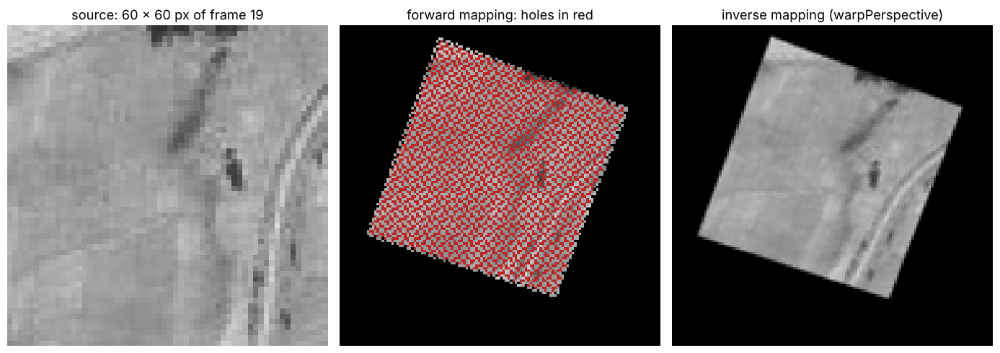

In [26]:
crop = A[430:490, 610:670]                                                   # 60 x 60 px of frame 19
th = np.radians(20)
Hz = np.array([[1.45*np.cos(th), -1.45*np.sin(th), 40],                         # rotate 20°, enlarge 1.45x,
               [1.45*np.sin(th),  1.45*np.cos(th),  5],                         # plus a little perspective
               [0.0006, 0.0002, 1]])
sz = (130, 130)

fwd = np.zeros(sz[::-1], np.uint8); hit = np.zeros(sz[::-1], bool)          # forward: send each source pixel
ys, xs = np.mgrid[:crop.shape[0], :crop.shape[1]]
dst = np.rint(project(np.c_[xs.ravel(), ys.ravel()].astype(float), Hz)).astype(int)
ok = (dst[:, 0] >= 0) & (dst[:, 0] < sz[0]) & (dst[:, 1] >= 0) & (dst[:, 1] < sz[1])
fwd[dst[ok, 1], dst[ok, 0]] = crop.ravel()[ok]; hit[dst[ok, 1], dst[ok, 0]] = True
inv = cv2.warpPerspective(crop, Hz, sz, flags=cv2.INTER_LINEAR)              # inverse, as OpenCV does it
foot = cv2.warpPerspective(np.full_like(crop, 1), Hz, sz, flags=cv2.INTER_NEAREST) > 0
foot = cv2.erode(foot.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0
print(f"forward mapping filled {hit[foot].mean():.0%} of the warped footprint; inverse mapping fills 100%")
fwd_rgb = np.dstack([fwd, fwd, fwd]); fwd_rgb[foot & ~hit] = (184, 40, 40)

fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
ax[0].imshow(crop, cmap='gray', vmin=0, vmax=255, interpolation='nearest'); ax[0].set_title("source: 60 × 60 px of frame 19")
ax[1].imshow(fwd_rgb, interpolation='nearest'); ax[1].set_title("forward mapping: holes in red")
ax[2].imshow(inv, cmap='gray', vmin=0, vmax=255, interpolation='nearest'); ax[2].set_title("inverse mapping (warpPerspective)")
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

### 9.2 — A canvas big enough for both

Frame 19 warped into frame 20's coordinates lands mostly at *negative* $x$ — off the left
edge. So: push the four corners of 19 through $H$, take the bounding box of those plus 20's
own corners, and prepend a translation $T$ that moves the box's top-left to $(0, 0)$.
Warp 19 by $T H$ and 20 by $T$.

In [27]:
H = cv2.findHomography(P, Q, cv2.USAC_MAGSAC, 3.0)[0]      # 19 -> 20

def canvas_for(H, a_shape, b_shape):
    ha, wa = a_shape[:2]; hb, wb = b_shape[:2]
    ca = project(np.array([[0, 0], [wa, 0], [wa, ha], [0, ha]], float), H)
    allc = np.r_[ca, [[0, 0], [wb, 0], [wb, hb], [0, hb]]]
    x0, y0 = np.floor(allc.min(0)); x1, y1 = np.ceil(allc.max(0))
    T = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]])
    return T, (int(x1 - x0), int(y1 - y0))

T, size = canvas_for(H, A.shape, B.shape)
print("corners of 19 in 20's frame:\n", np.round(project(np.array([[0, 0], [A.shape[1], 0],
      [A.shape[1], A.shape[0]], [0, A.shape[0]]], float), H)))
print(f"canvas {size[0]} x {size[1]},  T shifts by ({T[0, 2]:.0f}, {T[1, 2]:.0f})")

wa = cv2.warpPerspective(A, T @ H, size); ma = cv2.warpPerspective(np.full_like(A, 255), T @ H, size) > 0
wb = cv2.warpPerspective(B, T, size);     mb = cv2.warpPerspective(np.full_like(B, 255), T, size) > 0

corners of 19 in 20's frame:
 [[-389.  -26.]
 [ 549.  -25.]
 [ 527.  966.]
 [-385.  966.]]
canvas 1345 x 1026,  T shifts by (390, 26)


### 9.3 — Blending

Where both frames have data we must decide what to show.

* **Overwrite**: later image wins. Leaves a hard seam wherever exposure differs.
* **Average**: 50/50 in the overlap. Seams move to the overlap's edges, and anything that
  differs between the two (the forestry ink!) shows as a ghost.
* **Feather**: weight each image by its distance to its own border (a distance transform,
  L5), so each fades out smoothly where it ends.

Real stitchers go further: *multi-band* blending (Burt & Adelson 1983) feathers low
frequencies over a wide zone and high frequencies over a narrow one; *seam finding* picks a
cut through the overlap where the images agree; *gain compensation* evens out exposure first.

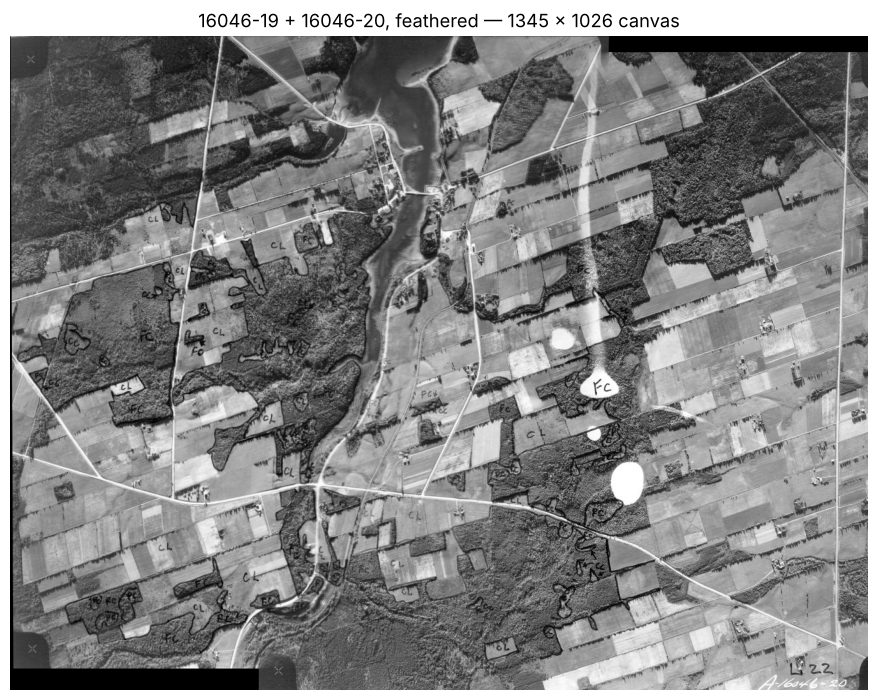

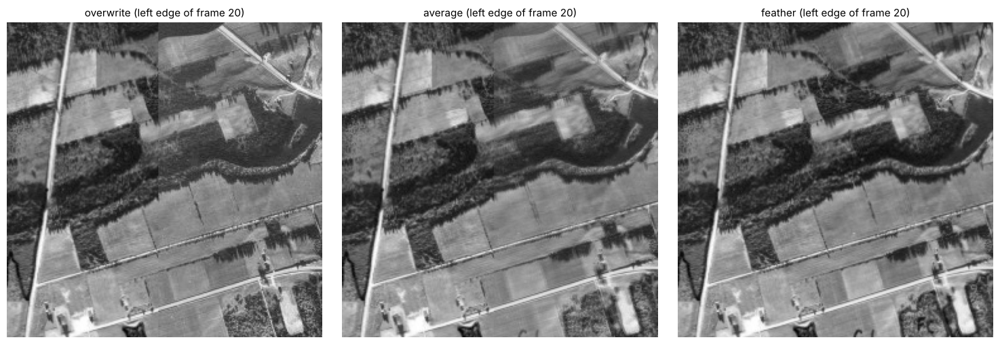

mean brightness in the overlap: 19 = 127.4, 20 = 114.0


In [28]:
fa, fb = wa.astype(np.float32), wb.astype(np.float32)
over = np.where(mb, fb, fa)
both = ma & mb
avg = np.where(both, (fa + fb) / 2, np.where(mb, fb, fa))
da_ = cv2.distanceTransform(ma.astype(np.uint8), cv2.DIST_L2, 5)
db_ = cv2.distanceTransform(mb.astype(np.uint8), cv2.DIST_L2, 5)
feather = (fa*da_ + fb*db_) / np.maximum(da_ + db_, 1e-6)
blends = {"overwrite": over, "average": avg, "feather": feather}
blends = {k: np.clip(v, 0, 255).astype(np.uint8) for k, v in blends.items()}

plt.figure(figsize=(15, 8.5)); plt.imshow(blends["feather"], cmap='gray'); plt.axis('off')
plt.title(f"16046-19 + 16046-20, feathered — {size[0]} × {size[1]} canvas"); plt.show()

# Zoom on the left edge of frame 20, where overwrite switches images
x_edge = int(T[0, 2])
ys_, xs_ = slice(80, 330), slice(x_edge - 120, x_edge + 130)
show([b[ys_, xs_] for b in blends.values()],
     [f"{k} (left edge of frame 20)" for k in blends], figw=15, figh=5)
gain = (fb[both] / np.maximum(fa[both], 1)).mean()
print(f"mean brightness in the overlap: 19 = {fa[both].mean():.1f}, 20 = {fb[both].mean():.1f}")

The seam in the overwrite image is an *exposure* seam: scanned contact prints are brighter
in the middle than at the edges (vignetting), so where frame 20's left edge meets frame 19's
centre, the brightness jumps. Average and feather hide it; the ink annotations, which exist
on one print and not the other, show through as ghosts in both.

---
## 10 · Panoramas: a camera that only rotates

When a camera with intrinsic matrix $K$ (focal length $f$ in pixels, principal point at the
image centre) rotates by $R$ about its optical centre, every point moves by

$$H = K\,R\,K^{-1}$$

— *whatever* the depth of the scene. So a rotating camera gives us a homography between any two
views, and that is how panoramas are stitched.

We do not have a tripod sequence, but pure rotation can be **simulated exactly** from one
photo, because depth does not matter. `beach2.jpg` is a phone photo (26 mm equivalent, so
$f \approx 1502$ px at 2000 px wide). We cut three 1000 × 750 views from it, each from a
virtual camera turned by a different yaw, pitch and roll — what you would get standing in
the same spot and turning. Then we forget the rotations and stitch the views from SIFT matches
alone.

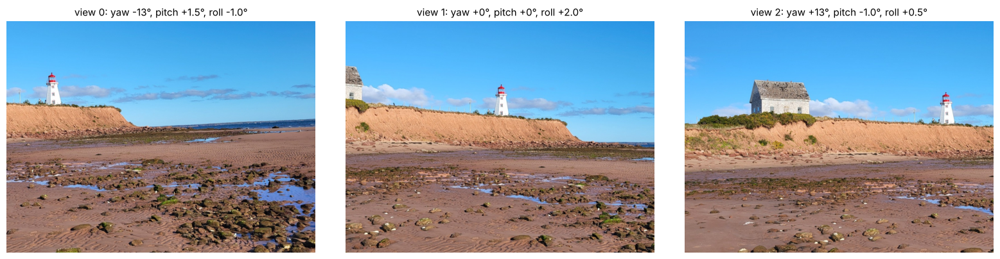

In [29]:
pano_src = cv2.imread("beach/beach2.jpg")
f = 1502.0
Hs, Ws = pano_src.shape[:2]
K_src = np.array([[f, 0, Ws/2], [0, f, Hs/2], [0, 0, 1]])
vw, vh = 1000, 750
K_v = np.array([[f, 0, vw/2], [0, f, vh/2], [0, 0, 1]])

def rot(yaw, pitch, roll):
    y, p, r = np.radians([yaw, pitch, roll])
    Ry = np.array([[np.cos(y), 0, np.sin(y)], [0, 1, 0], [-np.sin(y), 0, np.cos(y)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(p), -np.sin(p)], [0, np.sin(p), np.cos(p)]])
    Rz = np.array([[np.cos(r), -np.sin(r), 0], [np.sin(r), np.cos(r), 0], [0, 0, 1]])
    return Rz @ Rx @ Ry

POSES = [(-13, 1.5, -1.0), (0, 0, 2.0), (13, -1.0, 0.5)]           # yaw, pitch, roll in degrees
Rs = [rot(*p) for p in POSES]
# source pixel -> view pixel: view camera is the source camera rotated by R
views = [cv2.warpPerspective(pano_src, K_v @ R @ np.linalg.inv(K_src), (vw, vh), flags=cv2.INTER_LINEAR)
         for R in Rs]
show(views, [f"view {i}: yaw {p[0]:+}°, pitch {p[1]:+}°, roll {p[2]:+}°" for i, p in enumerate(POSES)],
     figw=16, figh=4)

In [30]:
gv = [cv2.cvtColor(v, cv2.COLOR_BGR2GRAY) for v in views]
feats = [sift.detectAndCompute(g, None) for g in gv]

def match_h(i, j, r=0.8, eps=3.0):
    (k1, d1), (k2, d2) = feats[i], feats[j]
    good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2) if m.distance < r * n.distance]
    p = np.float64([k1[m.queryIdx].pt for m in good]); q = np.float64([k2[m.trainIdx].pt for m in good])
    H, m = cv2.findHomography(p, q, cv2.RANSAC, eps)
    return H, p, q, m.ravel().astype(bool)

pano = {}
for i in (0, 2):                                     # each outer view -> the middle view
    H, p, q, m = match_h(i, 1)
    H_gt = K_v @ Rs[1] @ Rs[i].T @ np.linalg.inv(K_v)
    corners = np.array([[0, 0], [vw, 0], [vw, vh], [0, vh]], float)
    cerr = np.linalg.norm(project(corners, H) - project(corners, H_gt), axis=1).max()
    pano[i] = H
    print(f"view {i} -> view 1: {len(p)} candidates, {m.sum()} inliers ({100*m.mean():.0f}%), "
          f"worst corner vs K R K^-1: {cerr:.2f} px")

view 0 -> view 1: 2663 candidates, 2625 inliers (99%), worst corner vs K R K^-1: 0.10 px


view 2 -> view 1: 2340 candidates, 2301 inliers (98%), worst corner vs K R K^-1: 0.09 px


panorama canvas 1858 x 981


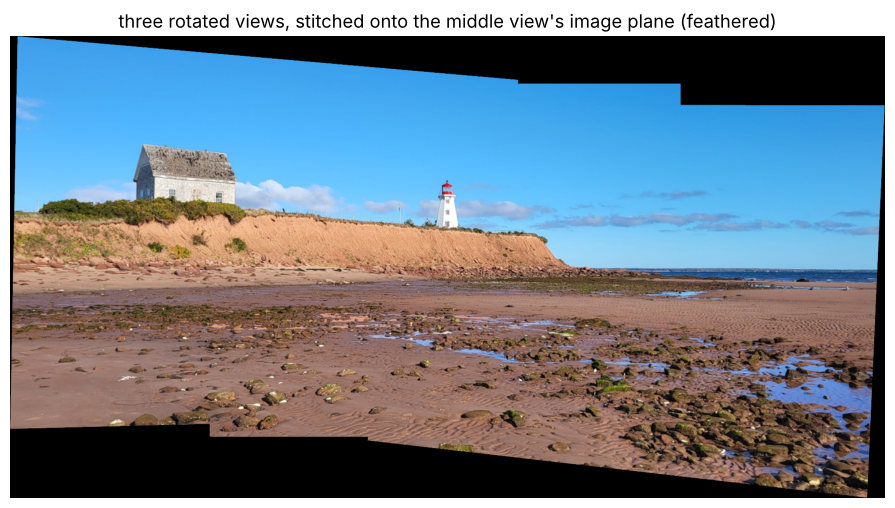

In [31]:
# Stitch all three into the middle view's plane
corners = np.array([[0, 0], [vw, 0], [vw, vh], [0, vh]], float)
allc = np.r_[corners, project(corners, pano[0]), project(corners, pano[2])]
x0, y0 = np.floor(allc.min(0)); x1, y1 = np.ceil(allc.max(0))
Tp = np.array([[1, 0, -x0], [0, 1, -y0], [0, 0, 1]]); psize = (int(x1 - x0), int(y1 - y0))
acc = np.zeros((psize[1], psize[0], 3), np.float32); wsum = np.zeros(psize[::-1], np.float32)
for i, Hi in ((0, pano[0]), (1, np.eye(3)), (2, pano[2])):
    m = cv2.warpPerspective(np.ones((vh, vw), np.uint8), Tp @ Hi, psize, flags=cv2.INTER_NEAREST)
    wgt = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    acc += cv2.warpPerspective(views[i], Tp @ Hi, psize).astype(np.float32) * wgt[..., None]
    wsum += wgt
pano_img = (acc / np.maximum(wsum, 1e-6)[..., None]).astype(np.uint8)
print(f"panorama canvas {psize[0]} x {psize[1]}")
plt.figure(figsize=(15, 6)); plt.imshow(cv2.cvtColor(pano_img, cv2.COLOR_BGR2RGB)); plt.axis('off')
plt.title("three rotated views, stitched onto the middle view's image plane (feathered)"); plt.show()

The stitched views reproduce the original photo, because the original photo *is* a picture on
one image plane — and so is a homography panorama. That is also its limit. On a plane, a
direction $\theta$ away from the centre lands at $x = f\tan\theta$, which runs off to infinity
as $\theta \to 90^\circ$. Wide panoramas are therefore projected onto a **cylinder**
($x = f\theta$) or a **sphere** instead — `cv2.Stitcher` does this by default.

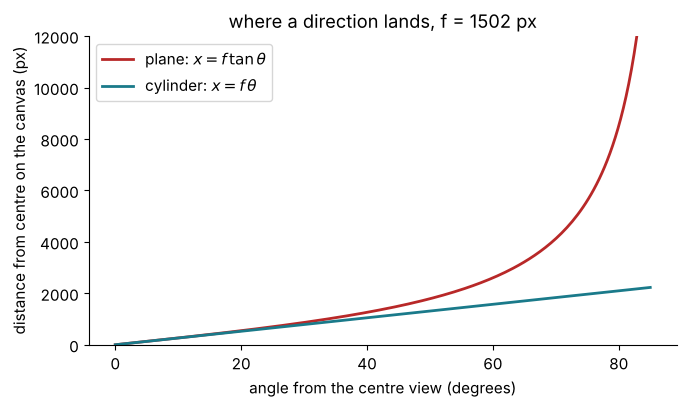

30°: plane     867 px   cylinder   786 px
60°: plane   2,602 px   cylinder 1,573 px
75°: plane   5,606 px   cylinder 1,966 px
85°: plane  17,168 px   cylinder 2,228 px


In [32]:
th = np.linspace(0, 85, 200)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(th, f*np.tan(np.radians(th)), c=RED, lw=2, label=r"plane: $x = f\,\tan\theta$")
ax.plot(th, f*np.radians(th), c=TEAL, lw=2, label=r"cylinder: $x = f\,\theta$")
ax.set_ylim(0, 12000); ax.set_xlabel("angle from the centre view (degrees)")
ax.set_ylabel("distance from centre on the canvas (px)")
ax.legend(); ax.set_title(f"where a direction lands, f = {f:.0f} px")
plt.tight_layout(); plt.show()
for t in (30, 60, 75, 85):
    print(f"{t:2d}°: plane {f*np.tan(np.radians(t)):7,.0f} px   cylinder {f*np.radians(t):5,.0f} px")

---
## 11 · When RANSAC lies

RANSAC **always returns the best model it found** — even when there is nothing to find.
Two real failures.

**(a) The photographer walked.** `beach1`, `beach2` and `beach3` were taken minutes apart
while walking along the shore. The camera moved metres between shots, the scene has depth
from 2 m to 2 km, and the views barely overlap. No homography relates them.

In [33]:
beach = [cv2.imread(f"beach/beach{k}.jpg") for k in (1, 2, 3)]
bg = [cv2.cvtColor(cv2.resize(b, (1000, 750), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY) for b in beach]
bf = [sift.detectAndCompute(g, None) for g in bg]

def accept(n_inl, n_match, alpha=8.0, beta=0.3):
    # Brown & Lowe (2007): accept an image match only if inliers > alpha + beta * matches.
    return n_inl > alpha + beta * n_match

fail_rows = []
for i, j in ((0, 1), (1, 2), (0, 2)):
    (k1, d1), (k2, d2) = bf[i], bf[j]
    good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
    p = np.float64([k1[m.queryIdx].pt for m in good]); q = np.float64([k2[m.trainIdx].pt for m in good])
    H, m = cv2.findHomography(p, q, cv2.RANSAC, 3.0)
    n = int(m.sum())
    fail_rows.append((f"beach{i+1} → beach{j+1}", len(good), n))
    print(f"beach{i+1} -> beach{j+1}: {len(good):3} candidates, {n:2} inliers, "
          f"needs > {8 + 0.3*len(good):.0f} -> {'ACCEPT' if accept(n, len(good)) else 'reject'};  H returned: {H is not None}")

beach1 -> beach2:  37 candidates,  6 inliers, needs > 19 -> reject;  H returned: True
beach2 -> beach3:  51 candidates,  7 inliers, needs > 23 -> reject;  H returned: True
beach1 -> beach3:  27 candidates,  3 inliers, needs > 16 -> reject;  H returned: True


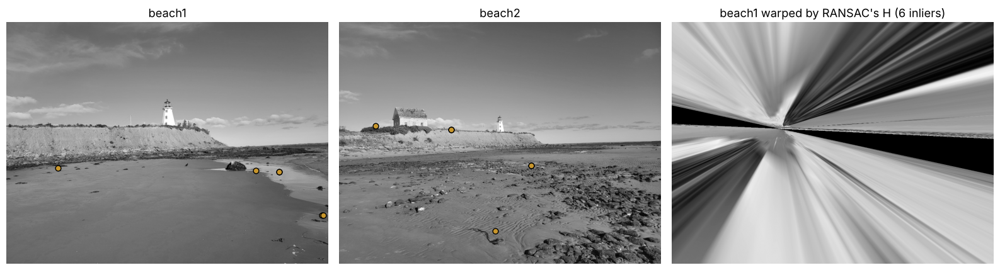

In [34]:
(k1, d1), (k2, d2) = bf[0], bf[1]
good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
p = np.float64([k1[m.queryIdx].pt for m in good]); q = np.float64([k2[m.trainIdx].pt for m in good])
Hb, mb_ = cv2.findHomography(p, q, cv2.RANSAC, 3.0); mb_ = mb_.ravel().astype(bool)
warped = cv2.warpPerspective(bg[0], Hb, (1000, 750))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, im, t in ((ax[0], bg[0], "beach1"), (ax[1], bg[1], "beach2"), (ax[2], warped, f"beach1 warped by RANSAC's H ({mb_.sum()} inliers)")):
    a.imshow(im, cmap='gray'); a.set_title(t); a.axis('off')
ax[0].scatter(*p[mb_].T, s=40, c=GOLD, edgecolors='k'); ax[1].scatter(*q[mb_].T, s=40, c=GOLD, edgecolors='k')
plt.tight_layout(); plt.show()

**(b) Ten years apart.** L7's cross-era pair: the 1958 and 1968 clips of the same fields.
SIFT + ratio test kept 133 matches and *one* was correct. What does RANSAC make of that?

In [35]:
RES = {1958: 1.1593543264609192, 1968: 0.5}
def to_grid(img, src_res, target=1.0):
    s = src_res / target
    wh = (int(round(img.shape[1]*s)), int(round(img.shape[0]*s)))
    return cv2.resize(img, wh, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
aer = {y: to_grid(cv2.imread(f"pei_{y}.png", cv2.IMREAD_GRAYSCALE), RES[y]) for y in (1958, 1968)}
side = min(min(a.shape) for a in aer.values())
C58, C68 = aer[1958][:side, :side], aer[1968][:side, :side]

k58, d58 = sift.detectAndCompute(C58, None); k68, d68 = sift.detectAndCompute(C68, None)
good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(d58, d68, k=2) if m.distance < 0.8 * n.distance]
p = np.float64([k58[m.queryIdx].pt for m in good]); q = np.float64([k68[m.trainIdx].pt for m in good])
Hx, mx = cv2.findHomography(p, q, cv2.RANSAC, 3.0); mx = mx.ravel().astype(bool)
print(f"1958 -> 1968: {len(good)} candidates, RANSAC inliers {mx.sum()}, "
      f"needs > {8 + 0.3*len(good):.0f} -> {'ACCEPT' if accept(mx.sum(), len(good)) else 'reject'}")

# How many inliers does pure chance produce?  Shuffle the partners and run RANSAC again.
rng = np.random.default_rng(0); chance = []
for _ in range(50):
    _, m = cv2.findHomography(p, q[rng.permutation(len(q))], cv2.RANSAC, 3.0)
    chance.append(int(m.sum()) if m is not None else 0)
print(f"random partners, 50 trials: inliers median {np.median(chance):.0f}, max {max(chance)}")
fail_rows.append(("1958 → 1968 clip", len(good), int(mx.sum())))

1958 -> 1968: 133 candidates, RANSAC inliers 9, needs > 48 -> reject


random partners, 50 trials: inliers median 8, max 12


RANSAC returns a homography in every case, with a handful of "inliers" — about what it finds
when the partners are shuffled at random. With few candidates, *some* four of them always
agree with *some* homography, and a few more fall within 3 px of it by luck. Always check the
inlier count against the number of candidates before you trust $H$. Brown & Lowe's rule —
inliers $> 8 + 0.3 \times$ matches — is a sensible default; on the 1958 pair it is 1,400+ against
a bar of about 500.

---
## ✏️ Try at home

Not graded. **A** and **C** are good preparation for AL6 on Friday.

### A — Adaptive RANSAC
Change `ransac_h` so that each time it finds a new best model it recomputes
$N = \log(1-p)/\log(1-w^4)$ from that model's inlier fraction $w$, and stops once it has done
$N$ iterations. How many iterations does it take on the ratio-0.8 candidates? On all
11,654 nearest-neighbour candidates?

### B — RANSAC for a translation
Write the $s = 1$ version (one match → a shift) and run it on all nearest-neighbour
candidates (no ratio test). How does it compare with AL5's median shift? With the homography?

### C — Three frames
Stitch 16046-19, -20 and -21 onto frame 20's plane: fit 19 → 20 and 21 → 20, build one
canvas from all twelve corners, and feather. Then try chaining instead: 19 → 20 and
20 → 21, so $H_{19\to21} = H_{20\to21}H_{19\to20}$. Compare $H_{19\to21}$ with a direct
fit between 19 and 21 (they overlap by about 15%).

### D — Break the homography
Take two photos of your desk while *moving* the phone sideways (not rotating it). Stitch
them. Where does it fail, and does the threshold $\varepsilon$ change which part of the
scene RANSAC chooses to align?